# 01 — Data and game (no AI calls)

**oil-agent-bench** puts AI models in the seat of a WTI trader for one year, under fixed rules, and asks whether they do better than doing nothing, holding oil, or a coin. It is the September **agent-alpha-bench** game (US stocks), narrowed to one market.

This first notebook checks the plumbing before any model is asked anything: the prices, the rules, one trade worked by hand, the two simple players, 1,000 random traders, and the checks that no player can see a price it could not have known. Everything here runs in about a minute.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from oilbench import rules
from oilbench.data import Market, load_or_download, expiry_dates
from oilbench.engine import Book
from oilbench.schema import Decision, parse_llm
from oilbench.prompt import build_base
from oilbench.prompt import MANDATES, build_payload, render_text, estimate_tokens
from oilbench.agents import Flat, BuyAndHold, RandomTrader
from oilbench.replay import run, decision_dates, season_span
from oilbench.metrics import scoreboard, random_traders_cached, beats, pnl_metrics

PRICES = ROOT / "data" / "wti_daily.csv"       # stays on this Mac, never committed
RESULTS = ROOT / "data" / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. The rules

All the rules sit in one short file, `oilbench/rules.py`, and every player plays under exactly these.

In [2]:
print(f"Account:        ${rules.INITIAL_CAPITAL:,.0f} paper, no leverage")
print(f"Positions:      {', '.join(rules.POSITIONS)} (long and short use the whole account)")
print(f"Costs:          {rules.FEE_RATE:.2%} of the amount traded on every fill (about $18 per WTI contract at $90)")
print(f"Disaster stop:  set by the game when a position opens, {rules.STOP_ATR_MULT:.0f} x the 14-day ATR from the entry price, "
      f"at most {rules.STOP_MAX_PCT:.0%}; never moved; players exit by choosing flat")
print(f"Year replayed:  {rules.WINDOW_START} to {rules.WINDOW_END}")
print(f"Prices:         front-month WTI as quoted, roll adjustment = {rules.ADJUST_ROLLS}")
print("Timing:         decide at the close, fill at the next open, stop checked against each day's low/high, marked at the close")

Account:        $10,000 paper, no leverage
Positions:      long, short, flat (long and short use the whole account)
Costs:          0.02% of the amount traded on every fill (about $18 per WTI contract at $90)
Disaster stop:  set by the game when a position opens, 3 x the 14-day ATR from the entry price, at most 15%; never moved; players exit by choosing flat
Year replayed:  2025-10-01 to 2026-09-30
Prices:         front-month WTI as quoted, roll adjustment = False
Timing:         decide at the close, fill at the next open, stop checked against each day's low/high, marked at the close


## 2. Prices

Daily open, high, low and close of the front-month WTI future (Yahoo Finance, `CL=F`). The file is downloaded once into `data/wti_daily.csv` and stays on this Mac; set `refresh=True` to download again.

In [3]:
raw = load_or_download(PRICES, refresh=False)
md_ = Market.from_raw(raw, adjust_rolls=rules.ADJUST_ROLLS)
year = md_.bars.loc[rules.WINDOW_START:rules.WINDOW_END]
span = season_span(md_)
print(f"{len(raw):,} trading days of prices, {raw.index[0].date()} to {raw.index[-1].date()}")
print(f"The season: {span['days']} decisions; the first trade can fill at the open of {span['first_fill']}, "
      f"the last mark is the close of {span['last_mark']}. Nothing outside this window is measured.")
print(f"WTI over the window: close ${year['close'].iloc[0]:.2f} on {year.index[0].date()}, ${year['close'].iloc[-1]:.2f} on {year.index[-1].date()} "
      f"({year['close'].iloc[-1] / year['close'].iloc[0] - 1:+.1%}); low ${year['low'].min():.2f}, high ${year['high'].max():.2f}")

4,222 trading days of prices, 2010-01-04 to 2026-10-19
The season: 250 decisions; the first trade can fill at the open of 2025-10-02, the last mark is the close of 2026-09-30. Nothing outside this window is measured.
WTI over the window: close $61.78 on 2025-10-01, $90.42 on 2026-09-30 (+46.4%); low $54.98, high $119.48


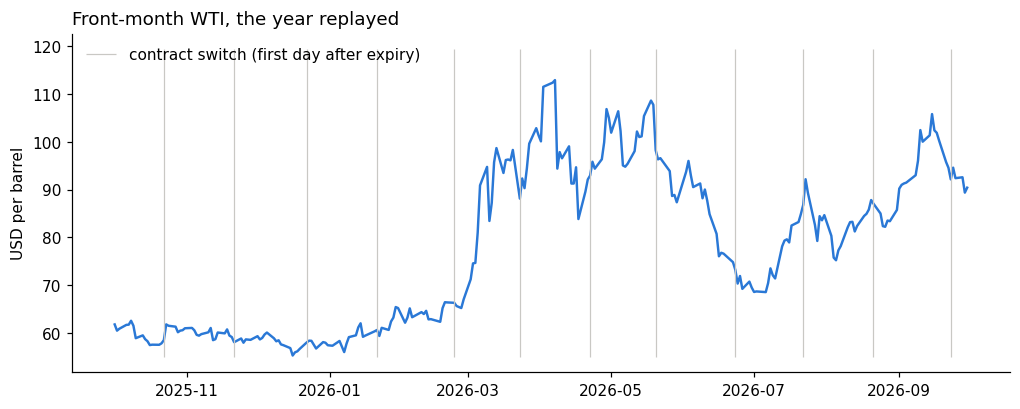

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(year.index, year["close"], color="#2a78d6", lw=1.6)
rolls = year.index[year["is_roll"]]
ax.vlines(rolls, year["low"].min(), year["high"].max(), color="#c9c8c4", lw=0.8, label="contract switch (first day after expiry)")
ax.set_ylabel("USD per barrel"); ax.set_title("Front-month WTI, the year replayed", loc="left"); ax.legend(frameon=False, loc="upper left")
plt.show()

### Why the quoted price, not a roll-adjusted one

Each month the front-month contract expires and the quote moves to the next contract. The usual fix is to set aside the price change on each switch day. On this year's data that fix did more harm than good: Yahoo's series does not show clearly when it switches, and two switch days were large real market moves. The table shows the move on each switch day; setting them all aside would have made holding oil look far better than it was. Decision of 19 October 2026: trade the quoted price, the same for every player. Details in `oilbench/data.py` and `BLUEPRINT.md`.

In [5]:
r = md_.bars["close"].pct_change()
switch = pd.DataFrame({"open": year.loc[rolls, "open"], "close": year.loc[rolls, "close"], "close-to-close move": r.loc[rolls]})
display(switch.style.format({"open": "{:.2f}", "close": "{:.2f}", "close-to-close move": "{:+.1%}"}))
adj = Market.from_raw(raw, adjust_rolls=True)
for name, m in [("quoted price (used)", md_), ("roll-adjusted (rejected)", adj)]:
    res = run(m, [BuyAndHold()])
    print(f"Hold oil all year, {name:<25} {pnl_metrics(res['buy_and_hold']['balance'])['total_return']:+.1%}")

,open,close,close-to-close move
date,,,
2025-10-22 00:00:00,57.59,58.50,+1.2%
2025-11-21 00:00:00,58.80,58.06,-1.8%
2025-12-22 00:00:00,56.63,58.01,+2.4%
2026-01-21 00:00:00,59.57,60.62,+0.5%
2026-02-23 00:00:00,65.89,66.31,-0.1%
2026-03-23 00:00:00,100.51,88.13,-10.4%
2026-04-22 00:00:00,90.00,92.96,+0.9%
2026-05-20 00:00:00,104.12,98.26,-8.8%
2026-06-23 00:00:00,74.14,73.21,-2.2%


Hold oil all year, quoted price (used)       +46.3%
Hold oil all year, roll-adjusted (rejected)  +79.9%


## 3. Point-in-time slicing — the single look-ahead guard

Every day a player sees `md.asof(t)`: only the prices up to and including day *t*. Fills use the next day's open, read explicitly by the engine.

In [6]:
dds = decision_dates(md_)
t = dds[100]
md_t = md_.asof(t)
assert md_t.bars.index[-1] == t and (md_t.bars.index <= t).all()
print(f"Decision date {t.date()}: {len(md_t.bars)} days visible, the last is {md_t.bars.index[-1].date()}; the trade fills on {md_.next_date(t).date()}")

Decision date 2026-02-25: 4059 days visible, the last is 2026-02-25; the trade fills on 2026-02-26


## 4. What a player sees, and the prompt

`build_payload()` returns what every player is allowed to see on a day: the last 60 daily bars, 26 weekly bars, eleven simple statistics and its own position. The AI players read it as text, after one of the three prompts (P1 the basic brief, P2 plus risk rules, P3 a structured brief).

In [7]:
payload = build_payload(md_t, Book().snapshot(float(md_t.bars["close"].iloc[-1])))
print("price:", payload["price"], "| position:", payload["position"])
pd.Series(payload["features"], name=str(t.date())).to_frame().T

price: 65.42 | position: {'position': 'flat', 'balance': 10000.0}


,ret_1d,ret_5d,ret_20d,ret_60d,vol_20d_ann,atr14_pct,sma20_pct,sma50_pct,hi20_pct,lo20_pct,rsi14
2026-02-25,-0.32,0.35,4.86,11.54,35.1,3.03,1.62,7.52,-2.76,7.04,58.0


In [8]:
text = render_text(payload)
print(MANDATES["P1"], "\n")
print(text[:900], "...\n")
for k, m in MANDATES.items():
    print(f"{k}: about {estimate_tokens(m + text):,} tokens per day")

You manage a $10,000 paper account that trades one market: front-month WTI crude oil futures. Each day, at the close, you choose the position you want for the next session: long (all of the account), short (all of the account) or flat (cash). Orders fill at the next open. Fees are 0.02% of the amount traded on every fill; there is no leverage. Every long or short carries a disaster stop set by the game at three times the 14-day average true range (ATR) from the entry price, but never more than 15% from it; the position is closed automatically if that price trades. You do not set or move this stop; you exit by choosing flat. Asking for the position you already hold keeps it. Each day you also state p_up, your probability that the next close will be above today's close; it is scored for accuracy on its own. 

DATA (as of the 2026-02-25 close):
{"decision_date":"2026-02-25","market":"front-month WTI crude oil futures, USD per barrel (continuous front-month price as quoted)","price":65.42,

### How an AI player decides

Each day the model reads one of the three prompts and that day's data, and writes its answer: a position (long, short or flat), its chance that oil closes higher tomorrow (`p_up`), a one-line thesis and a short reasoning. It never sets a stop: the game places the same disaster stop on every position (three ATRs from entry, at most 15%). Nothing in the code makes the choice for it. The decision is the model's own judgement, shaped by the prompt:

- **P1, the basic brief**: the rules only, no method. The model decides however it sees fit.
- **P2, plus risk rules**: the cost of changing position, flat when there is no clear view, 0.5 means no view; still no entry method.
- **P3, a structured brief**: read trend (20 and 60-day returns, distance to the 20 and 50-day averages), momentum (RSI, 5-day return) and location (distance to the 20-day high and low), weigh them yourself, and take a position when, on balance, the expected move beats the 0.04% round-trip cost; flat only with no view; keep a position while its reason holds.

**No threshold on `p_up`.** No level of `p_up` triggers a long or a short. The position and the chance of a rise are two separate answers, scored separately. A model may say 45% and stay flat, or 55% and go short because of a longer trend. This is deliberate: in September the chance was tied to a rule (no trade below 0.80) and both models simply wrote the smallest number the rule accepted.

**Every day is a new decision.** When a trade is open, the model is asked again each day, seeing its position, entry, the game's stop and unrealised P&L. Answering the same position keeps the trade; flat closes it at the next open; the opposite side reverses it. The disaster stop can also close it during any session.

**The reasoning is a window, not proof.** The written reasoning shows what the model says it checked. A language model's explanation does not always match how it reached its answer.

So the experiment does not test a trading rule. It tests whether the model's judgement, given only prices and one of these briefs, does better than doing nothing, holding oil, or a coin. (TimesFM is different: it forecasts, and a fixed rule written in advance turns its forecast into a position.)

## 5. The answer format

Each day an AI player must return one JSON object: a position, its probability that oil closes higher tomorrow (`p_up`), a short thesis and a short reasoning. No stop: the game sets it. A wrong answer is repaired once, then treated as "keep the current position".

In [9]:
answers = {
    "go short":                               {"reasoning": "Momentum negative.", "p_up": 0.42, "position": "short", "thesis": "Downtrend"},
    "keep an open long":                      {"reasoning": "Trend intact.", "p_up": 0.55, "position": "long"},
    "a stop sent anyway (accepted, ignored)": {"reasoning": "x", "p_up": 0.6, "position": "long", "stop_price": 80.0},
    "p_up missing":                           {"reasoning": "x", "position": "flat"},
    "position not long/short/flat":           {"reasoning": "x", "p_up": 0.5, "position": "buy"},
}
for name, ans in answers.items():
    a, err = parse_llm(ans)
    print(f"{name:<40} {'valid' if a else 'refused: ' + ' / '.join(s.strip() for s in err.splitlines()[1:3])}")

go short                                 valid
keep an open long                        valid
a stop sent anyway (accepted, ignored)   valid
p_up missing                             refused: p_up / Field required [type=missing, input_value={'reasoning': 'x', 'position': 'flat'}, input_type=dict]
position not long/short/flat             refused: position / Input should be 'long', 'short' or 'flat' [type=literal_error, input_value='buy', input_type=str]


## 6. The disaster stop

Every long or short gets the same stop, set by the game when the position opens: **three times the 14-day ATR** (average true range, the typical daily high-to-low move) **from the entry price, but never more than 15% from it**. It is never moved; a player exits by choosing flat. It is deliberately wide: a safety net for violent moves, not the reason most trades end.

How often would it have been hit this year? For an entry on every day of the year, the share of positions that reach the stop within a week and within a month:

In [10]:
closes, highs, lows = md_.bars["close"], md_.bars["high"], md_.bars["low"]
rows = []
for t_ in decision_dates(md_):
    i = md_.dates.get_loc(t_)
    b_ = build_base(md_.asof(t_)); entry = float(md_.bars["open"].iloc[i + 1])
    dist = min(rules.STOP_ATR_MULT * b_["_atr"], rules.STOP_MAX_PCT * entry)
    for hold in (5, 20):
        w = md_.bars.iloc[i + 1:i + 1 + hold]
        rows.append({"hold": hold, "distance": dist / entry,
                     "long hit": bool((w["low"] <= entry - dist).any()), "short hit": bool((w["high"] >= entry + dist).any())})
st = pd.DataFrame(rows)
summary = st.groupby("hold").agg(median_distance=("distance", "median"), long_hit=("long hit", "mean"), short_hit=("short hit", "mean"))
summary.index = ["held 1 week (5 days)", "held 1 month (20 days)"]
display(summary.style.format("{:.0%}"))
print(f"Stop distance over the year: from {st['distance'].min():.0%} to {st['distance'].max():.0%} of the entry price "
      f"(the 15% cap applied on {(st['distance'] >= rules.STOP_MAX_PCT - 1e-9).mean():.0%} of days)")

,median_distance,long_hit,short_hit
held 1 week (5 days),12%,7%,14%
held 1 month (20 days),12%,26%,49%


Stop distance over the year: from 7% to 15% of the entry price (the 15% cap applied on 41% of days)


### One trade, worked by hand

Go long on 11 March 2026 at the close, as the small model did in its first run: the order fills at the next open and the game places the disaster stop. Then hold until the model would have closed it on 20 April.

In [11]:
book = Book()
t0 = pd.Timestamp("2026-03-11")
b0 = build_base(md_.asof(t0))
d1 = md_.next_date(t0)
book.step(Decision("long", p_up=0.65), b0["_close"], d1, md_.bar(d1), atr=b0["_atr"])
print(f"Decided {t0.date()} at close {b0['_close']:.2f}; ATR that day {b0['_atr']:.2f} ({b0['_atr'] / b0['_close']:.1%}), so 3 ATRs = {3 * b0['_atr'] / book.entry_price:.0%}")
print(f"Filled {d1.date()} at open {book.entry_price:.2f}; disaster stop {book.stop:.2f} ({book.stop / book.entry_price - 1:+.1%}: the 15% cap applies)")
day = d1
while book.side and day < pd.Timestamp("2026-04-20"):
    nxt = md_.next_date(day); b_ = build_base(md_.asof(day))
    book.step(Decision("long" if nxt < pd.Timestamp("2026-04-20") else "flat"), b_["_close"], nxt, md_.bar(nxt), atr=b_["_atr"])
    day = nxt
print(f"Lowest price while held: {md_.bars.loc[d1:day, 'low'].min():.2f}; the stop was {'hit' if any(t.reason == 'stop' for t in book.trades) else 'never hit'}")
pd.DataFrame([vars(tr) for tr in book.trades]).round({"entry_price": 2, "exit_price": 2, "qty": 2, "pnl": 2, "pnl_pct": 4, "fees": 2})

Decided 2026-03-11 at close 87.25; ATR that day 8.39 (9.6%), so 3 ATRs = 28%
Filled 2026-03-12 at open 89.32; disaster stop 75.92 (-15.0%: the 15% cap applies)
Lowest price while held: 80.56; the stop was never hit


,side,entry_date,exit_date,entry_price,exit_price,qty,pnl,pnl_pct,fees,reason,holding_days,p_up_at_entry
0,1,2026-03-12,2026-04-20,89.32,89.0,111.93,-39.81,-0.0036,3.99,close,39,0.65


## 7. The simple players and 1,000 random traders

**Do nothing** keeps the cash. **Hold oil** buys at the first open and sells at the last close; it is the one player without the disaster stop, because it is a benchmark of what holding oil made, not a trader. Each **random trader** decides everything by coin flip under the same rules as the AI players, disaster stop included: when flat, a 50% chance a day to open, long or short at random; in a trade, a 10% chance a day to close. They have no information and no skill; they measure what luck alone produces.

In [12]:
base = run(md_, [Flat(), BuyAndHold()], log_dir=RESULTS / "baselines")
# played once for this exact window and saved under a name that carries the window
null = random_traders_cached(md_, RESULTS, rules.WINDOW_START, rules.WINDOW_END,
                             on_batch=lambda done, n, s: print(f"\r  random traders {done}/{n}  {s:.0f}s", end=""))
print("\n1,000 random traders for the window", null["window"].iloc[0])
sb = scoreboard(base)
sb["beats random traders (in 100)"] = [beats(null["total_return"], v) for v in sb["total_return"]]
sb[["total_return", "max_drawdown", "n_trades", "beats random traders (in 100)"]].style.format(
    {"total_return": "{:+.1%}", "max_drawdown": "{:.1%}", "n_trades": "{:.0f}", "beats random traders (in 100)": "{:.0f}"})


1,000 random traders for the window 2025-10-01_2026-09-29_250d_n1000


,total_return,max_drawdown,n_trades,beats random traders (in 100)
flat,+0.0%,0.0%,0,61
buy_and_hold,+46.3%,-39.3%,1,86


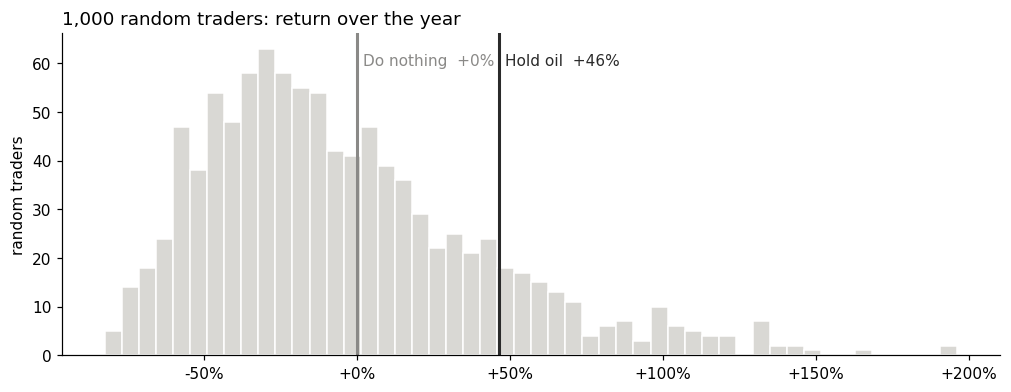

Random traders: median -13.9%; 90% of them between -61.7% and +89.0%; 39% made money; median 25 trades, 19% of their trades ended at the disaster stop


In [13]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.hist(null["total_return"], bins=50, color="#d9d8d4", edgecolor="white")
for name, c in [("flat", "#8a8987"), ("buy_and_hold", "#2a2a2a")]:
    v = sb.loc[name, "total_return"]; ax.axvline(v, color=c, lw=2)
    ax.annotate(f"{'Do nothing' if name == 'flat' else 'Hold oil'}  {v:+.0%}", (v, ax.get_ylim()[1] * 0.9), xytext=(4, 0), textcoords="offset points", color=c)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.set_title("1,000 random traders: return over the year", loc="left"); ax.set_ylabel("random traders")
plt.show()
q = null["total_return"].quantile([0.05, 0.5, 0.95])
print(f"Random traders: median {q[0.5]:+.1%}; 90% of them between {q[0.05]:+.1%} and {q[0.95]:+.1%}; "
      f"{(null['total_return'] > 0).mean():.0%} made money; median {null['n_trades'].median():.0f} trades, "
      f"{null['stopped_out'].sum() / null['n_trades'].sum():.0%} of their trades ended at the disaster stop")

## 8. Look-ahead checks

Kept in the notebook so they run every time:
1. every fill is on a later day than its decision;
2. no price in any day's prompt is dated after the decision date;
3. scrambling every price after a date changes nothing that any player saw before it.

In [14]:
log = base["buy_and_hold"]["log"]
assert (pd.to_datetime(log["fill_date"]) > pd.to_datetime(log["decision_date"])).all()
print("✓ every fill is after its decision date")

for t_ in dds[::20]:
    p = build_payload(md_.asof(t_), Book().snapshot(1.0))
    assert p["daily"]["last_date"] == str(t_.date())
print("✓ the last price in every prompt is the decision date's")

cut = dds[120]
scr = raw.copy(); scr.loc[scr.index > cut, ["open", "high", "low", "close"]] *= 1.5
seen = lambda m: [render_text(build_payload(m.asof(x), Book().snapshot(1.0))) for x in dds[:121]]
assert seen(md_) == seen(Market.from_raw(scr, adjust_rolls=rules.ADJUST_ROLLS))
print(f"✓ scrambling all prices after {cut.date()} changes nothing seen up to that day")

✓ every fill is after its decision date
✓ the last price in every prompt is the decision date's
✓ scrambling all prices after 2026-03-25 changes nothing seen up to that day


## 9. What this notebook established

- The prices, the rules, the engine and the scoring work end to end on the real year.
- The bar every AI player must clear: **do nothing** ends flat; **holding oil** ends at the figure above, through a deep drawdown; and the **random traders** spread very widely, so only a large result stands out from luck.
- Next: `02_small_model.ipynb` puts Qwen3 8B, running on this laptop, in the seat.